# 06 — Quelles tranches de salariés concentrent les départs ?
Objectif : repérer les **segments** (ancienneté, niveau, type de poste, rémunération relative, conditions de travail…) qui pèsent **peu dans les effectifs mais beaucoup dans les départs**. Exemple de lecture attendue : « les juniors mal payés représentent 10 % des effectifs mais 40 % des départs ».

**Indicateurs utilisés pour chaque segment**
- **Part des effectifs** et **part des départs** ;
- **Lift** = part des départs / part des effectifs = taux de départ du segment / taux global (lift 2 : le segment part deux fois plus que la moyenne) ;
- **Départs excédentaires** = départs observés − départs attendus au taux global (volume de départs « en trop » dans le segment) ;
- intervalle de confiance de Wilson sur le taux, test exact de Fisher, correction de Holm ou de Benjamini-Hochberg selon le cas.

| Section | Question |
|---|---|
| 1 | Définition des tranches (ancienneté, niveau, âge, poste, rémunération relative, conditions) |
| 2 | Quelles tranches simples sur-contribuent aux départs ? |
| 3 | Que donnent les croisements (ex. junior × mal payé, poste × niveau) ? |
| 4 | Recherche automatique de segments combinés (jusqu'à 3 critères), avec contrôle des tests multiples |
| 5 | Ces segments tiennent-ils sur des données non vues ? (validation par demi-échantillons) |
| 6 | Modèle de risque : quelle part des départs capte-t-on en ciblant 10 %, 20 % des effectifs ? |
| 7 | Synthèse |

**Précautions.** Les proportions ne sont pas annualisées (période non documentée) et décrivent des associations, pas des causes. Le genre n'est pas utilisé comme critère de segmentation (il est traité dans les notebooks 02 et 05). La recherche de segments est exploratoire : sélectionner les meilleurs segments sur 1 518 salariés surestime leur risque, d'où la section 5.

In [1]:
from pathlib import Path
import sys, warnings
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").exists():
    raise RuntimeError("Lancer depuis la racine du projet ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.data import load_data, export_table
from src.plots import save_figure

df = load_data()
Y = df.depart.to_numpy()
N, D = len(df), int(Y.sum())
TAUX = D / N
print(f"{N} salariés, {D} départs observés : taux global {TAUX:.1%} (non annualisé).")

1518 salariés, 248 départs observés : taux global 16.3% (non annualisé).


## 1. Définition des tranches
- **Niveau** : `JobLevel` regroupé en N1, N2, N3, N4-5 (les 9 salariés de niveau 0, modalité atypique du fichier, sont rattachés à N1).
- **Ancienneté** : `YearsAtCompany`. **Âge** : `Age`.
- **Rémunération relative** : rang percentile du revenu mensuel parmi les salariés **du même niveau**, découpé en tiers (paie basse = tiers inférieur de son niveau). C'est la mesure de « mal payé » : elle compare chacun à ses pairs et non à l'ensemble de l'entreprise (où le revenu reflète surtout le niveau). Le quartile de revenu absolu est conservé en complément.
- **Poste** : `JobRole` et `Department`.
- **Conditions de travail** : heures supplémentaires, voyages, situation familiale, distance, délai depuis la dernière promotion, satisfactions (poste, environnement, équilibre vie pro/perso ; les scores 0 et ≥ 5, atypiques, sont regroupés avec « faible » et « élevée »), stock-options.

Chaque modalité porte un libellé explicite pour que les segments combinés restent lisibles.

In [2]:
def cat(values, labels):
    return pd.Categorical(values, categories=labels, ordered=True)

df["niveau"] = pd.cut(df.JobLevel, [-1, 1, 2, 3, 5], labels=["Niveau 1", "Niveau 2", "Niveau 3", "Niveau 4-5"])
df["anciennete"] = pd.cut(df.YearsAtCompany, [-1, 1, 3, 6, 10, 100],
                          labels=["Ancienneté 0-1 an", "Ancienneté 2-3 ans", "Ancienneté 4-6 ans", "Ancienneté 7-10 ans", "Ancienneté >10 ans"])
df["age_tranche"] = pd.cut(df.Age, [0, 25, 30, 35, 45, 100],
                           labels=["Âge ≤25", "Âge 26-30", "Âge 31-35", "Âge 36-45", "Âge >45"])
# Rémunération relative : rang percentile du revenu parmi les salariés du même niveau
df["rang_paie"] = df.groupby("niveau", observed=True).MonthlyIncome.rank(pct=True)
df["paie_relative"] = pd.cut(df.rang_paie, [0, 1 / 3, 2 / 3, 1], labels=["Paie basse", "Paie médiane", "Paie haute"])
df["revenu_quartile"] = pd.qcut(df.MonthlyIncome, 4, labels=["Revenu Q1 (bas)", "Revenu Q2", "Revenu Q3", "Revenu Q4 (haut)"])
df["poste"] = df.JobRole
df["departement"] = df.Department
df["heures_sup"] = cat(np.where(df.OverTime == "Yes", "Heures sup", "Sans heures sup"), ["Heures sup", "Sans heures sup"])
df["voyages"] = cat(df.BusinessTravel.map({"Travel_Frequently": "Voyages fréquents", "Travel_Rarely": "Voyages rares", "Non-Travel": "Pas de voyage"}),
                    ["Voyages fréquents", "Voyages rares", "Pas de voyage"])
df["situation"] = cat(df.MaritalStatus.map({"Single": "Célibataire", "Married": "Marié(e)", "Divorced": "Divorcé(e)"}),
                      ["Célibataire", "Marié(e)", "Divorcé(e)"])
df["distance"] = pd.cut(df.DistanceFromHome, [-1, 5, 10, 100], labels=["Distance ≤5", "Distance 6-10", "Distance >10"])
df["delai_promo"] = pd.cut(df.YearsSinceLastPromotion, [-1, 1, 4, 100],
                           labels=["Dernière promo ≤1 an", "Dernière promo 2-4 ans", "Dernière promo >4 ans"])
for col, nom, lab in [("JobSatisfaction", "sat_poste", "Satisfaction poste"),
                      ("EnvironmentSatisfaction", "sat_env", "Satisfaction environnement"),
                      ("WorkLifeBalance", "equilibre", "Équilibre vie pro/perso")]:
    df[nom] = pd.cut(df[col], [-1, 2, 3, 100], labels=[f"{lab} faible (≤2)", f"{lab} moyenne (3)", f"{lab} élevée (≥4)"])
df["stock_options"] = cat(np.where(df.StockOptionLevel == 0, "Sans stock-options", "Avec stock-options"),
                          ["Sans stock-options", "Avec stock-options"])

PROFIL = {"niveau": "Niveau", "anciennete": "Ancienneté", "age_tranche": "Âge", "paie_relative": "Rémunération relative (au sein du niveau)",
          "revenu_quartile": "Revenu absolu", "poste": "Poste", "departement": "Département"}
CONDITIONS = {"heures_sup": "Heures supplémentaires", "voyages": "Voyages professionnels", "situation": "Situation familiale",
              "distance": "Distance domicile-travail", "delai_promo": "Délai depuis la dernière promotion",
              "sat_poste": "Satisfaction au poste", "sat_env": "Satisfaction environnement",
              "equilibre": "Équilibre vie pro/perso", "stock_options": "Stock-options"}
DIM_LABELS = {**PROFIL, **CONDITIONS}
assert df[list(DIM_LABELS)].notna().all().all(), "Tranche non définie pour certains salariés."
display(pd.crosstab(df.niveau, df.paie_relative, margins=True))

paie_relative,Paie basse,Paie médiane,Paie haute,All
niveau,,,,
Niveau 1,186,186,187,559
Niveau 2,181,182,182,545
Niveau 3,75,75,75,225
Niveau 4-5,63,63,63,189
All,505,506,507,1518


## 2. Tranches simples : poids dans les effectifs vs poids dans les départs
Pour chaque modalité : effectif, part des effectifs, départs, part des départs, taux de départ avec IC 95 %, lift, départs excédentaires, test exact de Fisher (modalité vs reste) et p-value corrigée par Holm sur l'ensemble des modalités testées.

In [3]:
def segment_table(data, dim):
    g = (data.groupby(dim, observed=True).depart.agg(effectif="size", departs="sum").reset_index()
         .rename(columns={dim: "segment"}))
    g["segment"] = g.segment.astype(str)
    g.insert(0, "dimension", dim)
    g["part_effectifs"] = g.effectif / N
    g["part_departs"] = g.departs / D
    g["taux_depart"] = g.departs / g.effectif
    lo, hi = proportion_confint(g.departs, g.effectif, method="wilson")
    g["ic95_bas"], g["ic95_haut"] = lo, hi
    g["lift"] = g.taux_depart / TAUX
    g["lift_ic95_bas"], g["lift_ic95_haut"] = lo / TAUX, hi / TAUX
    g["departs_excedentaires"] = g.departs - g.effectif * TAUX
    g["p_fisher"] = [stats.fisher_exact([[d, n - d], [D - d, (N - n) - (D - d)]])[1]
                     for n, d in zip(g.effectif, g.departs)]
    return g

dims = pd.concat([segment_table(df, c) for c in DIM_LABELS], ignore_index=True)
dims["p_holm"] = multipletests(dims.p_fisher, method="holm")[1]
dims.insert(1, "famille", np.where(dims.dimension.isin(PROFIL), "Profil", "Conditions"))
export_table(dims, "06_dimensions")
print(f"{len(dims)} modalités testées (correction de Holm sur l'ensemble).")

def phrase(mask, nom):
    n, d = int(mask.sum()), int(Y[mask].sum())
    return (f"{nom} : {n / N:.1%} des effectifs ({n} salariés), {d / D:.1%} des départs ({d}), "
            f"taux de départ {d / n:.1%} (lift ×{d / n / TAUX:.1f}).")

cols = ["dimension", "segment", "effectif", "part_effectifs", "part_departs", "taux_depart", "lift", "lift_ic95_bas", "lift_ic95_haut",
        "departs_excedentaires", "p_holm"]
sur = dims[(dims.effectif >= 30) & (dims.lift > 1)].sort_values("lift", ascending=False).head(15)
display(sur[cols].round(3))

58 modalités testées (correction de Holm sur l'ensemble).


,dimension,segment,effectif,part_effectifs,part_departs,taux_depart,lift,lift_ic95_bas,lift_ic95_haut,departs_excedentaires,p_holm
29,poste,Sales Representative,88,0.058,0.149,0.420,2.574,1.976,3.212,22.623,0.000
9,age_tranche,Âge ≤25,130,0.086,0.198,0.377,2.307,1.826,2.832,27.762,0.000
4,anciennete,Ancienneté 0-1 an,225,0.148,0.319,0.351,2.149,1.786,2.543,42.241,0.000
33,heures_sup,Heures sup,432,0.285,0.524,0.301,1.842,1.589,2.116,59.423,0.000
17,revenu_quartile,Revenu Q1 (bas),380,0.250,0.460,0.300,1.836,1.568,2.129,51.918,0.000
0,niveau,Niveau 1,559,0.368,0.597,0.265,1.621,1.407,1.854,56.675,0.000
35,voyages,Voyages fréquents,287,0.189,0.302,0.261,1.600,1.309,1.929,28.112,0.000
38,situation,Célibataire,484,0.319,0.504,0.258,1.581,1.354,1.830,45.928,0.000
56,stock_options,Sans stock-options,648,0.427,0.641,0.245,1.502,1.309,1.713,53.134,0.000
23,poste,Laboratory Technician,267,0.176,0.262,0.243,1.490,1.199,1.826,21.379,0.007


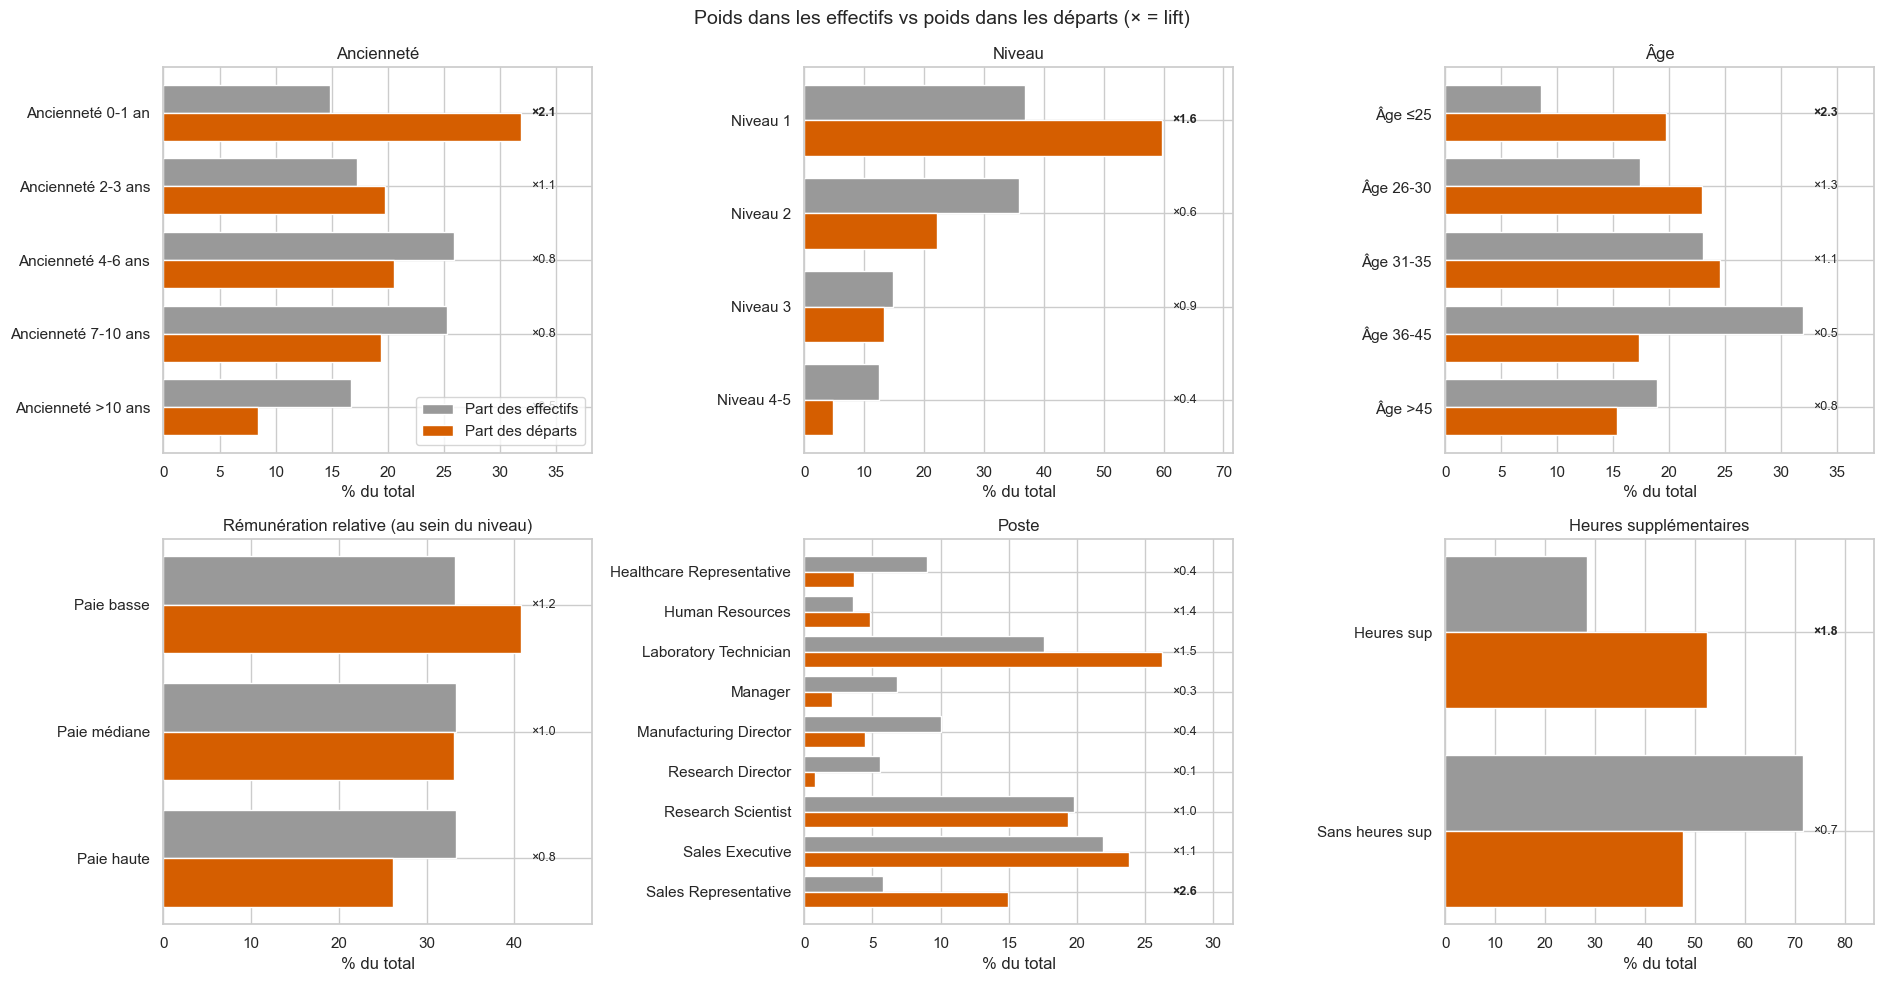

In [4]:
KEY = ["anciennete", "niveau", "age_tranche", "paie_relative", "poste", "heures_sup"]
fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for ax, dim in zip(axes.ravel(), KEY):
    t = dims[dims.dimension == dim].iloc[::-1]
    y = np.arange(len(t)); h = .38
    ax.barh(y + h / 2, t.part_effectifs * 100, h, label="Part des effectifs", color="#999999")
    ax.barh(y - h / 2, t.part_departs * 100, h, label="Part des départs", color="#D55E00")
    ax.set_yticks(y); ax.set_yticklabels(t.segment)
    xmax = max(t.part_effectifs.max(), t.part_departs.max()) * 100
    for yi, lift, n in zip(y, t.lift, t.effectif):
        ax.text(xmax * 1.03, yi, f"×{lift:.1f}", va="center", fontsize=9, fontweight="bold" if lift >= 1.5 else None)
    ax.set(xlim=(0, xmax * 1.2), xlabel="% du total", title=DIM_LABELS[dim])
axes[0, 0].legend(loc="lower right")
fig.suptitle("Poids dans les effectifs vs poids dans les départs (× = lift)", fontsize=14)
save_figure(fig, "06_effectifs_vs_departs")

## 3. Croisements : junior × mal payé, poste × niveau…
Les tranches simples masquent les effets combinés. Les cellules de moins de 15 salariés ne sont pas colorées. La p-value unilatérale (hypergéométrique, équivalente au test exact de Fisher unilatéral) mesure la sur-représentation des départs ; elle n'est pas corrigée ici (lecture descriptive).

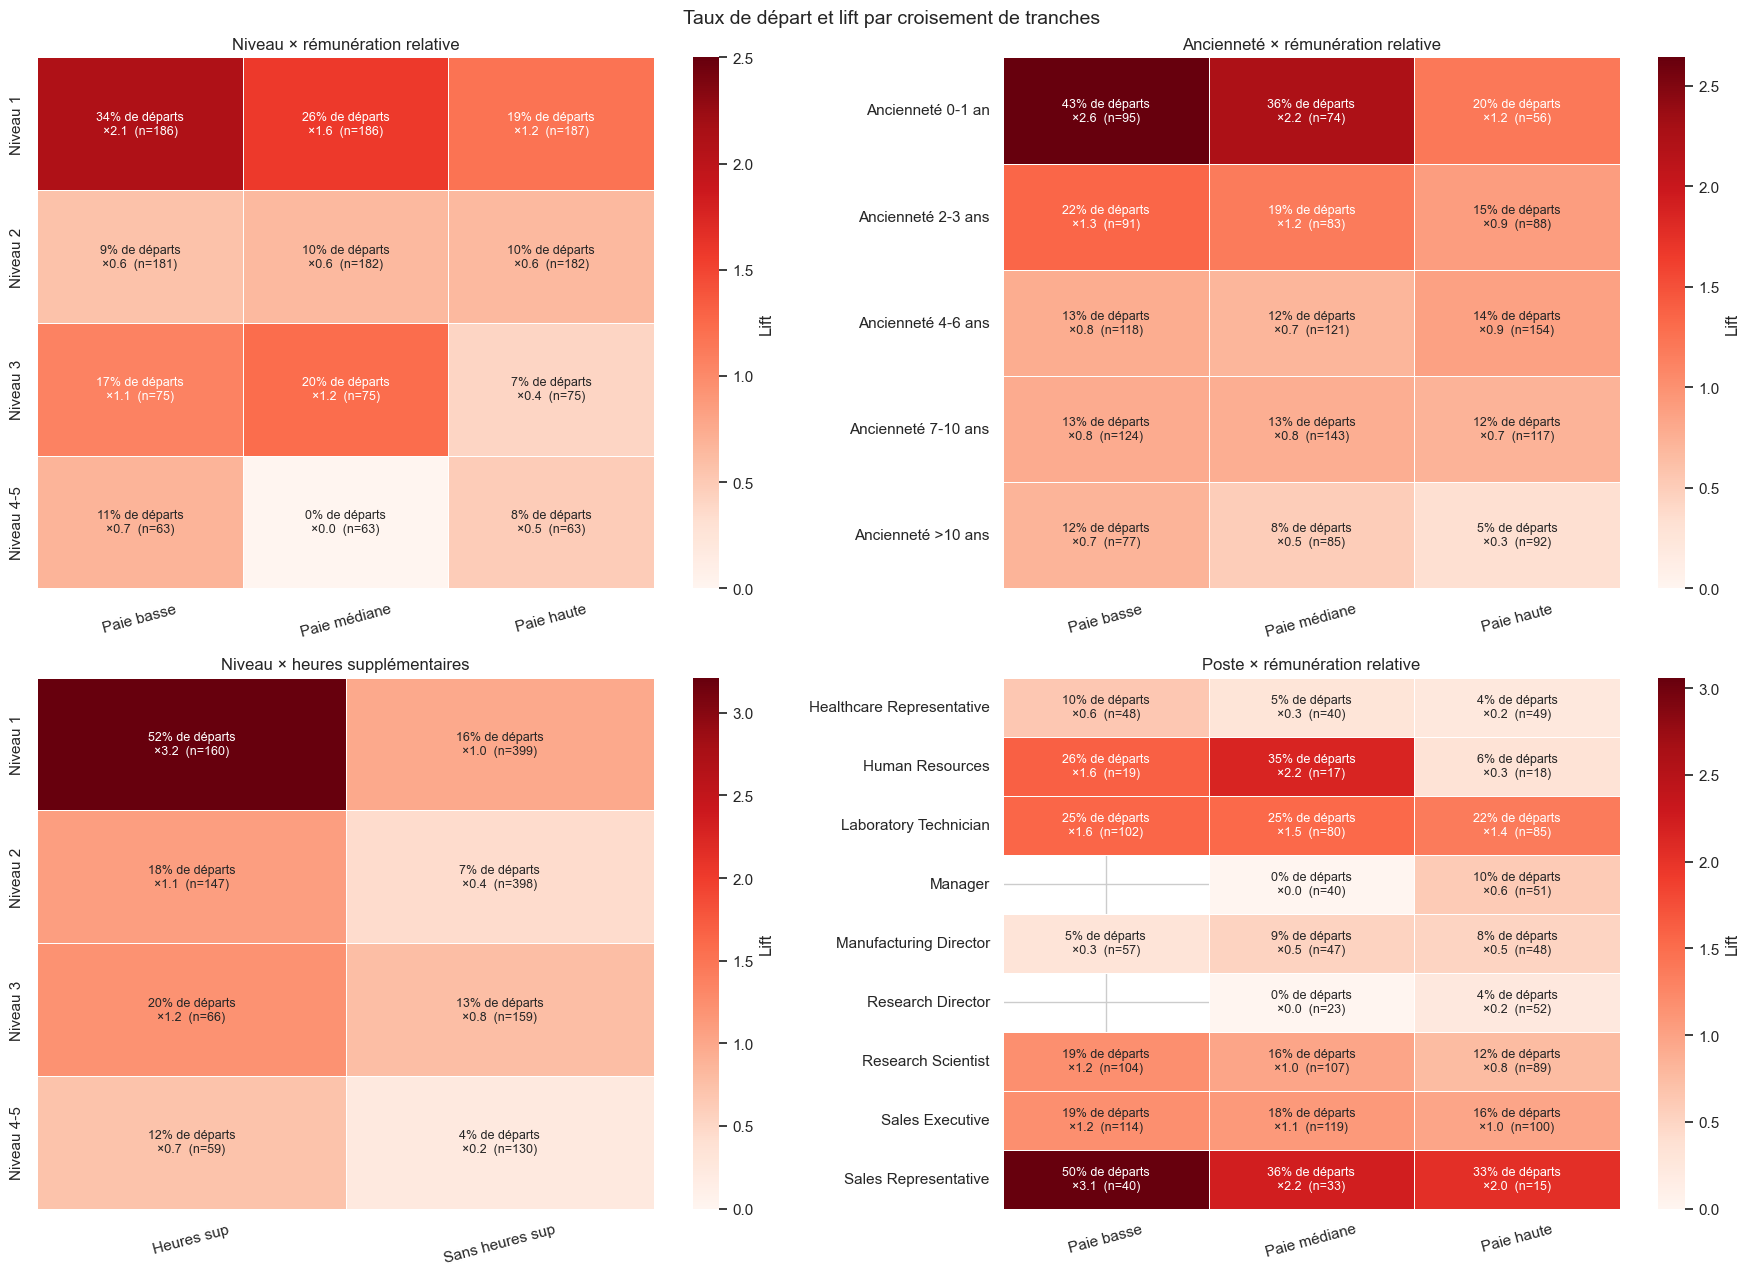

Juniors (niveau 1) à paie basse : 12.3% des effectifs (186 salariés), 25.8% des départs (64), taux de départ 34.4% (lift ×2.1).
Ancienneté ≤3 ans et paie basse : 12.3% des effectifs (186 salariés), 24.6% des départs (61), taux de départ 32.8% (lift ×2.0).
Niveau 1 avec heures sup : 10.5% des effectifs (160 salariés), 33.9% des départs (84), taux de départ 52.5% (lift ×3.2).
Ancienneté ≤3 ans, niveau 1 : 19.3% des effectifs (293 salariés), 39.1% des départs (97), taux de départ 33.1% (lift ×2.0).


In [5]:
def croisement(row, col):
    t = (df.groupby([row, col], observed=True).depart.agg(effectif="size", departs="sum").reset_index()
         .rename(columns={row: "ligne", col: "colonne"}))
    t[["ligne", "colonne"]] = t[["ligne", "colonne"]].astype(str)
    t.insert(0, "croisement", f"{row} x {col}")
    t["part_effectifs"] = t.effectif / N
    t["part_departs"] = t.departs / D
    t["taux_depart"] = t.departs / t.effectif
    t["lift"] = t.taux_depart / TAUX
    t["departs_excedentaires"] = t.departs - t.effectif * TAUX
    t["p_unilateral"] = stats.hypergeom.sf(t.departs - 1, N, D, t.effectif)
    return t

def heatmap(ax, t, row, col, titre, min_n=15):
    rows = [c for c in df[row].cat.categories if c in set(t.ligne)] if hasattr(df[row], "cat") else sorted(t.ligne.unique())
    cols_ = [c for c in df[col].cat.categories if c in set(t.colonne)] if hasattr(df[col], "cat") else sorted(t.colonne.unique())
    P = {v: t.pivot(index="ligne", columns="colonne", values=v).reindex(index=rows, columns=cols_)
         for v in ["lift", "taux_depart", "effectif"]}
    annot = pd.DataFrame("", index=rows, columns=cols_)
    for r in rows:
        for c in cols_:
            n = P["effectif"].loc[r, c]
            if not np.isnan(n):
                annot.loc[r, c] = (f"n={int(n)}" if n < min_n else
                                   f"{P['taux_depart'].loc[r, c]:.0%} de départs\n×{P['lift'].loc[r, c]:.1f}  (n={int(n)})")
    shown = P["lift"].where(P["effectif"] >= min_n)
    sns.heatmap(shown, annot=annot, fmt="", cmap="Reds", vmin=0, vmax=max(2.5, np.nanmax(shown.to_numpy())),
                cbar_kws={"label": "Lift"}, ax=ax, linewidths=.5, annot_kws={"fontsize": 9})
    ax.set(title=titre, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=15)

PAIRES = [("niveau", "paie_relative", "Niveau × rémunération relative"),
          ("anciennete", "paie_relative", "Ancienneté × rémunération relative"),
          ("niveau", "heures_sup", "Niveau × heures supplémentaires"),
          ("poste", "paie_relative", "Poste × rémunération relative")]
croisements = pd.concat([croisement(r, c) for r, c, _ in PAIRES], ignore_index=True)
export_table(croisements, "06_croisements")

fig, axes = plt.subplots(2, 2, figsize=(18, 13))
for ax, (r, c, titre) in zip(axes.ravel(), PAIRES):
    heatmap(ax, croisements[croisements.croisement == f"{r} x {c}"], r, c, titre)
fig.suptitle("Taux de départ et lift par croisement de tranches", fontsize=14)
save_figure(fig, "06_croisements")

print(phrase((df.niveau == "Niveau 1") & (df.paie_relative == "Paie basse"), "Juniors (niveau 1) à paie basse"))
print(phrase((df.YearsAtCompany <= 3) & (df.paie_relative == "Paie basse"), "Ancienneté ≤3 ans et paie basse"))
print(phrase((df.niveau == "Niveau 1") & (df.OverTime == "Yes"), "Niveau 1 avec heures sup"))
print(phrase((df.YearsAtCompany <= 3) & (df.niveau == "Niveau 1"), "Ancienneté ≤3 ans, niveau 1"))

## 4. Recherche automatique de segments combinés
On énumère toutes les combinaisons de 1 à 3 critères parmi les 16 dimensions (hors genre), avec au moins **40 salariés** et **10 départs** par segment. Pour chaque segment, un test hypergéométrique unilatéral (sur-représentation des départs) est corrigé par **Benjamini-Hochberg** sur l'ensemble des segments testés (taux de fausses découvertes de 5 %).

Un segment est retenu s'il remplit toutes les conditions suivantes :
1. q-value ≤ 0,05, lift ≥ 1,5 et **taille ≤ 20 % des effectifs** (une tranche qui couvre la moitié de l'entreprise n'est pas ciblable ; les grandes tranches restent lisibles en section 2) ;
2. **chaque critère ajouté améliore réellement le taux** d'au moins 15 % par rapport au sous-segment sans ce critère (pas de critère décoratif) ;
3. il ne recouvre pas à plus de 50 % un segment déjà retenu (dédoublonnage).

Deux classements, parmi les segments ciblables : **volume** (départs excédentaires : où part-on le plus ?) et **intensité** (lift : où le risque est-il le plus fort ?).

In [6]:
MINE_DIMS = list(DIM_LABELS)
CODES, LEVELS = [], []
for c in MINE_DIMS:
    codes, uniques = pd.factorize(df[c].astype(str))
    CODES.append(codes); LEVELS.append(list(uniques))
CODES = np.column_stack(CODES)
IMPOSSIBLE = {frozenset((MINE_DIMS.index("poste"), MINE_DIMS.index("departement")))}  # emboîtés

def member(codes, items):
    return np.logical_and.reduce([codes[:, j] == l for j, l in items])

def label(items):
    return " + ".join(LEVELS[j][l] for j, l in items)

def mine(idx, kmax=3, min_n=40, min_d=10):
    y, codes = Y[idx], CODES[idx]
    n_tot, d_tot = len(idx), int(y.sum())
    parts = []
    for k in range(1, kmax + 1):
        for combo in combinations(range(len(MINE_DIMS)), k):
            if any(s <= set(combo) for s in IMPOSSIBLE):
                continue
            shape = [len(LEVELS[j]) for j in combo]
            key = np.ravel_multi_index([codes[:, j] for j in combo], shape)
            size = int(np.prod(shape))
            n = np.bincount(key, minlength=size)
            d = np.bincount(key, weights=y, minlength=size).astype(int)
            keep = np.flatnonzero((n >= min_n) & (d >= min_d))
            if keep.size:
                lv = np.unravel_index(keep, shape)
                items = [tuple((combo[a], int(lv[a][i])) for a in range(k)) for i in range(keep.size)]
                parts.append(pd.DataFrame({"items": items, "k": k, "n": n[keep], "d": d[keep]}))
    seg = pd.concat(parts, ignore_index=True)
    seg["taux"] = seg.d / seg.n
    seg["lift"] = seg.taux / (d_tot / n_tot)
    seg["excedent"] = seg.d - seg.n * d_tot / n_tot
    seg["p"] = stats.hypergeom.sf(seg.d - 1, n_tot, d_tot, seg.n)
    seg["q"] = multipletests(seg.p, method="fdr_bh")[1]
    return seg

def select(seg, idx, top=8, rank_by="excedent", min_lift=1.5, q_max=0.05, gain=1.15, overlap_max=.5, max_part=.20):
    y, codes = Y[idx], CODES[idx]
    cand = seg[(seg.q <= q_max) & (seg.lift >= min_lift) & (seg.n <= max_part * len(idx))].sort_values(rank_by, ascending=False)
    chosen, masks = [], []
    for r in cand.itertuples():
        if len(r.items) > 1:
            parents = [y[member(codes, r.items[:i] + r.items[i + 1:])].mean() for i in range(len(r.items))]
            if r.taux < gain * max(parents):
                continue
        m = member(codes, r.items)
        if any((m & mm).sum() / min(m.sum(), mm.sum()) > overlap_max for mm in masks):
            continue
        chosen.append(r._asdict()); masks.append(m)
        if len(chosen) == top:
            break
    return pd.DataFrame(chosen)

ALL = np.arange(N)
seg_full = mine(ALL)
print(f"{len(seg_full)} segments testés (1 à 3 critères) ; "
      f"{int((seg_full.q <= .05).sum())} avec q ≤ 0,05, dont {int(((seg_full.q <= .05) & (seg_full.lift >= 1.5)).sum())} avec lift ≥ 1,5.")
top_volume = select(seg_full, ALL, rank_by="excedent")
top_intensite = select(seg_full, ALL, rank_by="lift")

4746 segments testés (1 à 3 critères) ; 1220 avec q ≤ 0,05, dont 1167 avec lift ≥ 1,5.


In [7]:
rng = np.random.default_rng(42)

def half_split(rng):
    i1, i0 = np.flatnonzero(Y == 1), np.flatnonzero(Y == 0)
    a = np.concatenate([rng.choice(i1, len(i1) // 2, replace=False), rng.choice(i0, len(i0) // 2, replace=False)])
    return a, np.setdiff1d(ALL, a)

HALVES = [half_split(rng) for _ in range(200)]

def describe(sel, liste):
    rows = []
    for r in sel.itertuples():
        m = member(CODES, r.items)
        lo, hi = proportion_confint(r.d, r.n, method="wilson")
        stab = np.mean([Y[a][m[a]].mean() / Y[a].mean() >= 1.5 for a, _ in HALVES if m[a].sum() > 0])
        rows.append(dict(classement=liste, segment=label(r.items), criteres=r.k, effectif=r.n, part_effectifs=r.n / N,
                         departs=r.d, part_departs=r.d / D, taux_depart=r.taux, ic95_bas=lo, ic95_haut=hi, lift=r.lift,
                         departs_excedentaires=r.excedent, q_value=r.q, stabilite_demi_echantillons=stab))
    return pd.DataFrame(rows)

segments = pd.concat([describe(top_volume, "Volume (départs excédentaires)"),
                      describe(top_intensite, "Intensité (lift)")], ignore_index=True)
export_table(segments, "06_segments_top")
for liste, g in segments.groupby("classement", sort=False):
    print(f"\n=== {liste} ===")
    display(g.drop(columns="classement").round(3))
    for r in g.itertuples():
        print(f"- {r.segment} : {r.part_effectifs:.1%} des effectifs, {r.part_departs:.1%} des départs (lift ×{r.lift:.1f})")


=== Volume (départs excédentaires) ===


,segment,criteres,effectif,part_effectifs,departs,part_departs,taux_depart,ic95_bas,ic95_haut,lift,departs_excedentaires,q_value,stabilite_demi_echantillons
0,Niveau 1 + Heures sup,2,160,0.105,84,0.339,0.525,0.448,0.601,3.214,57.860,0.0,1.000
1,Niveau 1 + Sans stock-options,2,264,0.174,97,0.391,0.367,0.312,0.427,2.249,53.870,0.0,1.000
2,Heures sup + Sans stock-options,2,184,0.121,82,0.331,0.446,0.376,0.518,2.728,51.939,0.0,1.000
3,Ancienneté 0-1 an,1,225,0.148,79,0.319,0.351,0.292,0.416,2.149,42.241,0.0,1.000
4,Satisfaction poste faible (≤2) + Sans stock-op...,2,252,0.166,82,0.331,0.325,0.271,0.385,1.992,40.830,0.0,0.990
5,Heures sup + Satisfaction environnement faible...,2,149,0.098,60,0.242,0.403,0.327,0.483,2.465,35.657,0.0,1.000
6,Satisfaction environnement faible (≤2) + Sans ...,2,264,0.174,77,0.310,0.292,0.240,0.349,1.785,33.870,0.0,0.975
7,Sales + Sans stock-options,2,203,0.134,67,0.270,0.330,0.269,0.397,2.020,33.835,0.0,0.995


- Niveau 1 + Heures sup : 10.5% des effectifs, 33.9% des départs (lift ×3.2)
- Niveau 1 + Sans stock-options : 17.4% des effectifs, 39.1% des départs (lift ×2.2)
- Heures sup + Sans stock-options : 12.1% des effectifs, 33.1% des départs (lift ×2.7)
- Ancienneté 0-1 an : 14.8% des effectifs, 31.9% des départs (lift ×2.1)
- Satisfaction poste faible (≤2) + Sans stock-options : 16.6% des effectifs, 33.1% des départs (lift ×2.0)
- Heures sup + Satisfaction environnement faible (≤2) : 9.8% des effectifs, 24.2% des départs (lift ×2.5)
- Satisfaction environnement faible (≤2) + Sans stock-options : 17.4% des effectifs, 31.0% des départs (lift ×1.8)
- Sales + Sans stock-options : 13.4% des effectifs, 27.0% des départs (lift ×2.0)

=== Intensité (lift) ===


,segment,criteres,effectif,part_effectifs,departs,part_departs,taux_depart,ic95_bas,ic95_haut,lift,departs_excedentaires,q_value,stabilite_demi_echantillons
8,Revenu Q1 (bas) + Heures sup + Célibataire,3,42,0.028,30,0.121,0.714,0.564,0.828,4.372,23.138,0.0,1.0
9,Niveau 1 + Ancienneté 0-1 an + Heures sup,3,46,0.030,32,0.129,0.696,0.552,0.809,4.258,24.485,0.0,1.0
10,Ancienneté 0-1 an + Revenu Q1 (bas) + Célibataire,3,54,0.036,36,0.145,0.667,0.534,0.778,4.081,27.178,0.0,1.0
11,Niveau 1 + Heures sup + Voyages fréquents,3,41,0.027,27,0.109,0.659,0.505,0.784,4.031,20.302,0.0,1.0
12,Âge ≤25 + Heures sup,2,41,0.027,27,0.109,0.659,0.505,0.784,4.031,20.302,0.0,1.0
13,Sales + Heures sup + Célibataire,3,49,0.032,32,0.129,0.653,0.513,0.771,3.997,23.995,0.0,1.0
14,Niveau 1 + Heures sup + Distance >10,3,46,0.030,29,0.117,0.630,0.486,0.755,3.859,21.485,0.0,1.0
15,Niveau 1 + Voyages fréquents + Célibataire,3,41,0.027,25,0.101,0.610,0.457,0.743,3.732,18.302,0.0,1.0


- Revenu Q1 (bas) + Heures sup + Célibataire : 2.8% des effectifs, 12.1% des départs (lift ×4.4)
- Niveau 1 + Ancienneté 0-1 an + Heures sup : 3.0% des effectifs, 12.9% des départs (lift ×4.3)
- Ancienneté 0-1 an + Revenu Q1 (bas) + Célibataire : 3.6% des effectifs, 14.5% des départs (lift ×4.1)
- Niveau 1 + Heures sup + Voyages fréquents : 2.7% des effectifs, 10.9% des départs (lift ×4.0)
- Âge ≤25 + Heures sup : 2.7% des effectifs, 10.9% des départs (lift ×4.0)
- Sales + Heures sup + Célibataire : 3.2% des effectifs, 12.9% des départs (lift ×4.0)
- Niveau 1 + Heures sup + Distance >10 : 3.0% des effectifs, 11.7% des départs (lift ×3.9)
- Niveau 1 + Voyages fréquents + Célibataire : 2.7% des effectifs, 10.1% des départs (lift ×3.7)


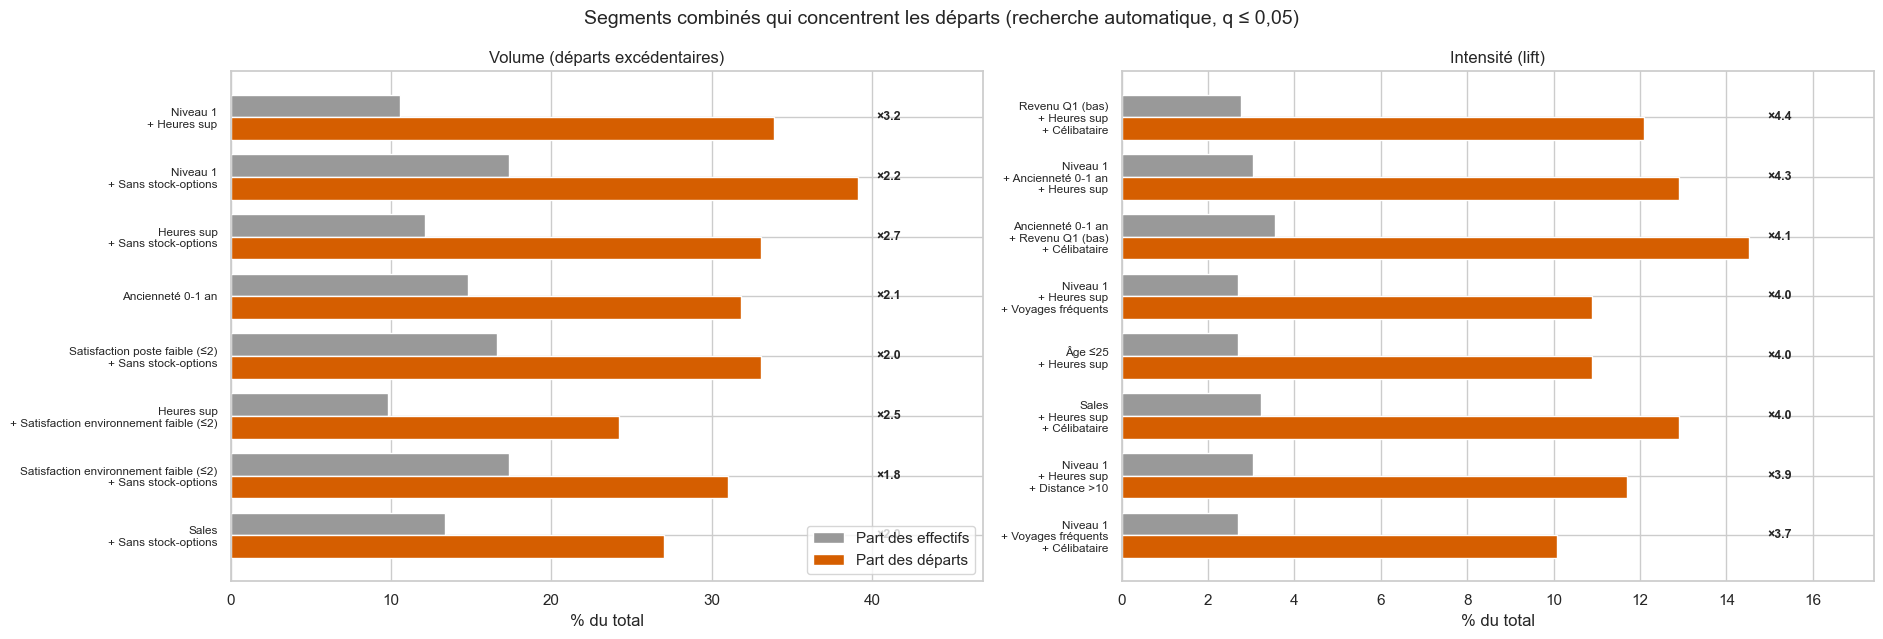

,nb_segments,part_effectifs_cumulee,part_departs_cumulee,taux_depart_union
0,1,0.105,0.339,0.525
1,2,0.229,0.528,0.376
2,3,0.300,0.657,0.357
3,4,0.372,0.726,0.319
4,5,0.434,0.786,0.296
5,6,0.466,0.815,0.285
6,7,0.515,0.843,0.267
7,8,0.539,0.863,0.262


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(19, 6.5))
for ax, (liste, g) in zip(axes, segments.groupby("classement", sort=False)):
    g = g.iloc[::-1]
    y = np.arange(len(g)); h = .38
    ax.barh(y + h / 2, g.part_effectifs * 100, h, color="#999999", label="Part des effectifs")
    ax.barh(y - h / 2, g.part_departs * 100, h, color="#D55E00", label="Part des départs")
    ax.set_yticks(y); ax.set_yticklabels([s.replace(" + ", "\n+ ") for s in g.segment], fontsize=8.5)
    xmax = max(g.part_effectifs.max(), g.part_departs.max()) * 100
    for yi, lift in zip(y, g.lift):
        ax.text(xmax * 1.03, yi, f"×{lift:.1f}", va="center", fontsize=9, fontweight="bold")
    ax.set(xlim=(0, xmax * 1.2), xlabel="% du total", title=liste)
axes[0].legend(loc="lower right")
fig.suptitle("Segments combinés qui concentrent les départs (recherche automatique, q ≤ 0,05)", fontsize=14)
save_figure(fig, "06_segments_top")

# Couverture cumulée des segments du classement « volume »
masks = [member(CODES, r.items) for r in top_volume.itertuples()]
cum = []
union = np.zeros(N, dtype=bool)
for k, (m, r) in enumerate(zip(masks, top_volume.itertuples()), start=1):
    union |= m
    cum.append(dict(nb_segments=k, part_effectifs_cumulee=union.mean(), part_departs_cumulee=Y[union].sum() / D,
                    taux_depart_union=Y[union].mean()))
cum = pd.DataFrame(cum)
display(export_table(cum, "06_couverture_cumulee").round(3))

## 5. Les segments tiennent-ils hors échantillon ?
Choisir les meilleurs segments parmi des milliers de candidats **gonfle mécaniquement** leur lift (effet de sélection). Deux contrôles :
- **Validation par demi-échantillons** : 40 fois, on découpe les salariés en deux moitiés stratifiées, on cherche et retient les meilleurs segments sur la moitié A (mêmes règles, seuils d'effectif divisés par 2), puis on mesure leur lift sur la moitié B, jamais vue. L'écart entre lift de découverte et lift de validation quantifie l'optimisme ;
- **Stabilité** (colonne ci-dessus) : part de 200 demi-échantillons aléatoires dans lesquels le segment garde un lift ≥ 1,5.

In [9]:
rng_v = np.random.default_rng(7)
rows = []
for s in range(40):
    a, b = half_split(rng_v)
    seg_a = mine(a, min_n=20, min_d=5)
    for classement, rank in [("Volume", "excedent"), ("Intensité", "lift")]:
        sel = select(seg_a, a, top=5, rank_by=rank)
        taux_b = Y[b].mean()
        for r in sel.itertuples():
            mb = member(CODES[b], r.items)
            if mb.sum():
                rows.append(dict(split=s, classement=classement, criteres=r.k, lift_decouverte=r.lift,
                                 lift_validation=Y[b][mb].mean() / taux_b, effectif_validation=int(mb.sum())))
val = pd.DataFrame(rows)
resume = (val.groupby("classement").agg(segments_retenus=("split", "size"),
                                        lift_decouverte_moyen=("lift_decouverte", "mean"),
                                        lift_validation_moyen=("lift_validation", "mean"),
                                        lift_validation_median=("lift_validation", "median"),
                                        part_validation_sup_1=("lift_validation", lambda x: (x > 1).mean()),
                                        part_validation_sup_1_5=("lift_validation", lambda x: (x >= 1.5).mean()))
          .reset_index())
resume["taux_de_conservation_excedent"] = (resume.lift_validation_moyen - 1) / (resume.lift_decouverte_moyen - 1)
display(export_table(resume, "06_validation_segments").round(3))
print("Lecture : taux de conservation = part de l'excès de risque (lift - 1) retrouvée sur les données non vues.")

,classement,segments_retenus,lift_decouverte_moyen,lift_validation_moyen,lift_validation_median,part_validation_sup_1,part_validation_sup_1_5,taux_de_conservation_excedent
0,Intensité,200,4.409,3.570,3.631,0.995,0.99,0.754
1,Volume,200,2.501,2.408,2.249,1.000,0.99,0.938


Lecture : taux de conservation = part de l'excès de risque (lift - 1) retrouvée sur les données non vues.


## 6. Modèle de risque : combien de départs capte-t-on en ciblant 10 % ou 20 % des effectifs ?
Les segments ci-dessus sont lisibles mais figés. Pour savoir **jusqu'où on peut concentrer** les départs, on estime un score de risque par régression logistique pénalisée (L2) sur les variables disponibles (hors genre, identifiants, constantes et taux journaliers/horaires/mensuels sans interprétation documentée). Les scores sont des **prédictions hors échantillon** : validation croisée stratifiée à 5 plis répétée 5 fois, probabilités moyennées. On classe ensuite les salariés par risque décroissant et on lit la **courbe de concentration** (part des départs captée par les X % les plus à risque).

AUC hors échantillon : 0.839


,part_effectifs,effectif,departs_captes,part_departs_captee,taux_depart,lift
0,0.05,76,67,0.270,0.882,5.396
1,0.10,152,110,0.444,0.724,4.430
2,0.15,228,141,0.569,0.618,3.785
3,0.20,304,155,0.625,0.510,3.121
4,0.30,455,184,0.742,0.404,2.475
5,0.40,607,204,0.823,0.336,2.057
6,0.50,759,215,0.867,0.283,1.734


Les 10% de salariés au risque prédit le plus élevé regroupent 44% des départs (taux 72%, lift ×4.4).
Les 20% de salariés au risque prédit le plus élevé regroupent 62% des départs (taux 51%, lift ×3.1).


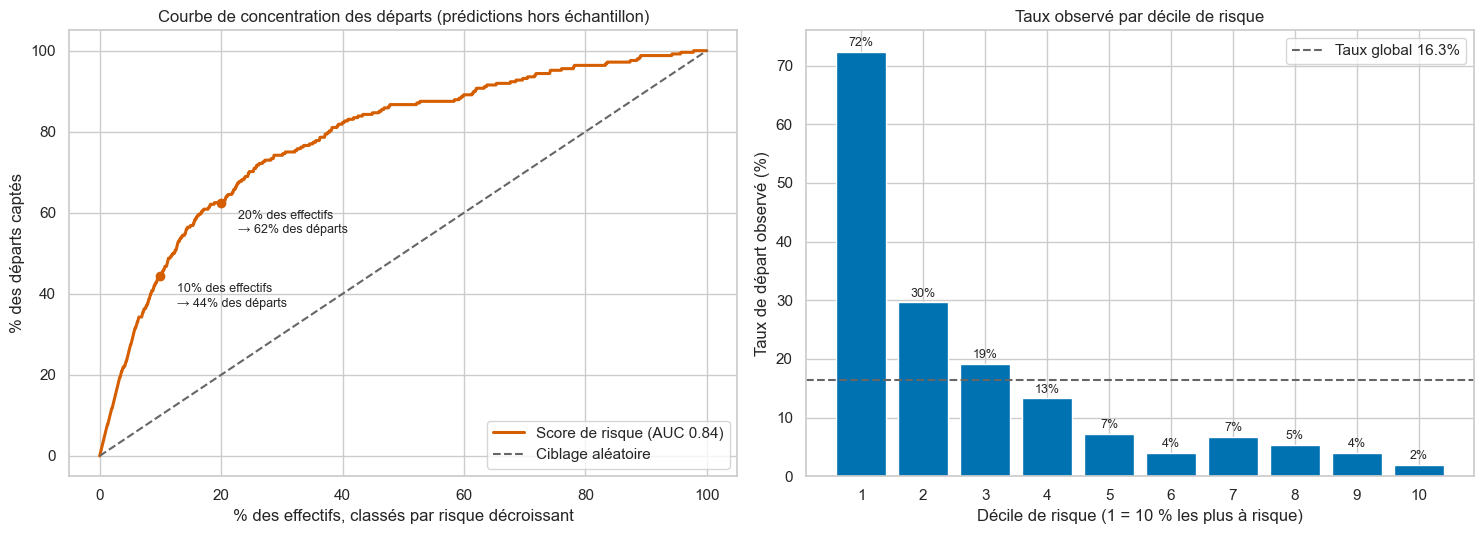

In [10]:
df["log_revenu"] = np.log(df.MonthlyIncome)
NUM = ["Age", "log_revenu", "rang_paie", "DistanceFromHome", "JobLevel", "NumCompaniesWorked", "PercentSalaryHike",
       "TotalWorkingYears", "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion",
       "YearsWithCurrManager", "StockOptionLevel", "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
       "RelationshipSatisfaction", "JobInvolvement", "PerformanceRating", "Education"]
CATS = ["BusinessTravel", "Department", "JobRole", "MaritalStatus", "OverTime", "EducationField"]
X = df[NUM + CATS]

def make_model():
    pre = ColumnTransformer([("num", StandardScaler(), NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), CATS)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=0.3, max_iter=2000))])

REPEATS = 5
oof = np.zeros(N)
for r in range(REPEATS):
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=r).split(X, Y):
        oof[te] += make_model().fit(X.iloc[tr], Y[tr]).predict_proba(X.iloc[te])[:, 1] / REPEATS
auc = roc_auc_score(Y, oof)
print(f"AUC hors échantillon : {auc:.3f}")

order = np.argsort(-oof, kind="stable")
cum_dep = np.cumsum(Y[order]) / D
cum_eff = np.arange(1, N + 1) / N
paliers = []
for p in [.05, .10, .15, .20, .30, .40, .50]:
    k = int(round(p * N))
    paliers.append(dict(part_effectifs=p, effectif=k, departs_captes=int(Y[order][:k].sum()),
                        part_departs_captee=cum_dep[k - 1], taux_depart=Y[order][:k].mean(),
                        lift=Y[order][:k].mean() / TAUX))
gains = pd.DataFrame(paliers)
display(export_table(gains, "06_gains").round(3))
for r in gains[gains.part_effectifs.isin([.10, .20])].itertuples():
    print(f"Les {r.part_effectifs:.0%} de salariés au risque prédit le plus élevé regroupent {r.part_departs_captee:.0%} des départs "
          f"(taux {r.taux_depart:.0%}, lift ×{r.lift:.1f}).")

decile = pd.qcut(pd.Series(oof).rank(method="first"), 10, labels=False)
dec = (pd.DataFrame({"decile": 10 - decile, "depart": Y}).groupby("decile").depart.agg(effectif="size", departs="sum", taux="mean")
       .sort_index().reset_index())
dec["part_departs"] = dec.departs / D
export_table(dec.rename(columns={"decile": "decile_risque_1_le_plus_eleve"}), "06_deciles_risque")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.plot(np.r_[0, cum_eff] * 100, np.r_[0, cum_dep] * 100, color="#D55E00", lw=2.2, label=f"Score de risque (AUC {auc:.2f})")
ax.plot([0, 100], [0, 100], "--", color="#666666", label="Ciblage aléatoire")
for p in [.10, .20]:
    k = int(round(p * N)); ax.scatter(p * 100, cum_dep[k - 1] * 100, color="#D55E00", zorder=3)
    ax.annotate(f"{p:.0%} des effectifs\n→ {cum_dep[k - 1]:.0%} des départs", (p * 100, cum_dep[k - 1] * 100),
                textcoords="offset points", xytext=(12, -22), fontsize=9)
ax.set(xlabel="% des effectifs, classés par risque décroissant", ylabel="% des départs captés",
       title="Courbe de concentration des départs (prédictions hors échantillon)")
ax.legend(loc="lower right")
ax = axes[1]
ax.bar(dec.decile.astype(str), dec.taux * 100, color="#0072B2")
ax.axhline(TAUX * 100, ls="--", color="#666666", label=f"Taux global {TAUX:.1%}")
for i, r in dec.iterrows():
    ax.text(i, r.taux * 100 + 1, f"{r.taux:.0%}", ha="center", fontsize=9)
ax.set(xlabel="Décile de risque (1 = 10 % les plus à risque)", ylabel="Taux de départ observé (%)", title="Taux observé par décile de risque")
ax.legend()
save_figure(fig, "06_gains")

In [11]:
# Profil du décile à plus haut risque (20 % des effectifs) : quelles tranches y retrouve-t-on ?
df["risque_eleve"] = np.isin(np.arange(N), order[: int(round(.2 * N))])
prof = []
for dim in ["niveau", "anciennete", "paie_relative", "heures_sup", "voyages", "situation", "poste"]:
    t = df.groupby(dim, observed=True).risque_eleve.agg(effectif="size", part_classee_risque_eleve="mean").reset_index()
    t.insert(0, "dimension", dim); t = t.rename(columns={dim: "segment"}); t["segment"] = t.segment.astype(str)
    prof.append(t)
prof = pd.concat(prof, ignore_index=True)
display(export_table(prof, "06_profil_risque_eleve").round(3))
df = df.drop(columns="risque_eleve")

,dimension,segment,effectif,part_classee_risque_eleve
0,niveau,Niveau 1,559,0.322
1,niveau,Niveau 2,545,0.167
2,niveau,Niveau 3,225,0.084
3,niveau,Niveau 4-5,189,0.074
4,anciennete,Ancienneté 0-1 an,225,0.364
5,anciennete,Ancienneté 2-3 ans,262,0.298
6,anciennete,Ancienneté 4-6 ans,393,0.201
7,anciennete,Ancienneté 7-10 ans,384,0.112
8,anciennete,Ancienneté >10 ans,254,0.087
9,paie_relative,Paie basse,505,0.261


## 7. Synthèse
Tableau final : les segments simples et combinés à retenir, avec leur poids dans les effectifs et dans les départs.

In [12]:
synth = segments[["classement", "segment", "effectif", "part_effectifs", "part_departs", "taux_depart", "lift",
                  "departs_excedentaires", "q_value", "stabilite_demi_echantillons"]].copy()
display(export_table(synth, "06_synthese").round(3))

,classement,segment,effectif,part_effectifs,part_departs,taux_depart,lift,departs_excedentaires,q_value,stabilite_demi_echantillons
0,Volume (départs excédentaires),Niveau 1 + Heures sup,160,0.105,0.339,0.525,3.214,57.860,0.0,1.000
1,Volume (départs excédentaires),Niveau 1 + Sans stock-options,264,0.174,0.391,0.367,2.249,53.870,0.0,1.000
2,Volume (départs excédentaires),Heures sup + Sans stock-options,184,0.121,0.331,0.446,2.728,51.939,0.0,1.000
3,Volume (départs excédentaires),Ancienneté 0-1 an,225,0.148,0.319,0.351,2.149,42.241,0.0,1.000
4,Volume (départs excédentaires),Satisfaction poste faible (≤2) + Sans stock-op...,252,0.166,0.331,0.325,1.992,40.830,0.0,0.990
5,Volume (départs excédentaires),Heures sup + Satisfaction environnement faible...,149,0.098,0.242,0.403,2.465,35.657,0.0,1.000
6,Volume (départs excédentaires),Satisfaction environnement faible (≤2) + Sans ...,264,0.174,0.310,0.292,1.785,33.870,0.0,0.975
7,Volume (départs excédentaires),Sales + Sans stock-options,203,0.134,0.270,0.330,2.020,33.835,0.0,0.995
8,Intensité (lift),Revenu Q1 (bas) + Heures sup + Célibataire,42,0.028,0.121,0.714,4.372,23.138,0.0,1.000
9,Intensité (lift),Niveau 1 + Ancienneté 0-1 an + Heures sup,46,0.030,0.129,0.696,4.258,24.485,0.0,1.000


## Conclusion

**Les départs sont très concentrés, mais pas exactement là où l'intuition « junior mal payé » le suggère.** Taux global : 16,3 % (248 départs sur 1 518, non annualisé).

**1. Lecture de l'exemple demandé.** Les juniors (niveau 1) à paie basse (tiers inférieur de leur niveau) représentent **12,3 % des effectifs et 25,8 % des départs** (taux 34 %, lift ×2,1). Le sur-départ est réel mais moins extrême que dans l'exemple illustratif (10 % / 40 %). Le profil qui s'en rapproche vraiment est **niveau 1 avec heures supplémentaires : 10,5 % des effectifs, 33,9 % des départs** (taux 52 %, lift ×3,2).

**2. Tranches simples les plus sur-contributrices** (toutes significatives après correction de Holm) :
| Tranche | Part des effectifs | Part des départs | Lift |
|---|---|---|---|
| Sales Representative | 5,8 % | 14,9 % | ×2,6 |
| Âge ≤ 25 ans | 8,6 % | 19,8 % | ×2,3 |
| Ancienneté 0-1 an | 14,8 % | 31,9 % | ×2,1 |
| Heures supplémentaires | 28,5 % | 52,4 % | ×1,8 |
| Niveau 1 | 36,8 % | 59,7 % | ×1,6 |

**3. La rémunération relative n'agit que chez les juniors.** Au niveau 1, le taux de départ passe de 34 % (paie basse) à 19 % (paie haute) ; aux niveaux 2 et 4-5, il n'y a pas de gradient net. Parmi les entrants (ancienneté 0-1 an), 43 % des salariés à paie basse sont partis contre 20 % à paie haute. Chez les Sales Representatives, la paie basse cumule 50 % de départs (n = 40).

**4. Segments combinés (4 746 testés, correction Benjamini-Hochberg).** Les segments ciblables (≤ 20 % des effectifs) les plus lourds en volume sont : niveau 1 + heures sup (10,5 % des effectifs, 33,9 % des départs), niveau 1 sans stock-options (17,4 % / 39,1 %), heures sup sans stock-options (12,1 % / 33,1 %). Les trois premiers segments réunis couvrent **30 % des effectifs et 66 % des départs**. Les plus intenses atteignent 60 à 70 % de départs (lift ×3,7 à ×4,4) pour 3 % des effectifs : par exemple revenu bas + heures sup + célibataire (42 salariés, 30 départs), niveau 1 + ancienneté 0-1 an + heures sup (46 salariés, 32 départs).

**5. Plafond de concentration.** Un score de risque (régression logistique, validation croisée, AUC 0,84) permet de cibler **les 10 % de salariés les plus à risque, qui regroupent 44 % des départs** (taux 72 %), et **les 20 % les plus à risque, 62 % des départs**. C'est la meilleure réponse à la question « quelle part des départs capte-t-on en ciblant X % des effectifs ? ».

**6. Robustesse.** Sur des demi-échantillons jamais vus, les segments retenus conservent 94 % de leur excès de risque pour le classement volume (lift 2,5 → 2,4) et 75 % pour le classement intensité (lift 4,4 → 3,6) : la sélection gonfle les lifts des petits segments, mais l'essentiel tient. Les segments les plus étroits sont donc à lire comme des ordres de grandeur.

### Recommandations pour O-zone Telecom
1. **Plafonner les heures supplémentaires des niveaux 1** : c'est le segment le plus lourd en volume et le plus actionnable.
2. **Sécuriser la première année** (ancienneté 0-1 an, ≤ 25 ans) : parcours d'intégration, suivi à 3, 6 et 12 mois, revue salariale à l'embauche.
3. **Revoir la politique salariale d'entrée au niveau 1** : l'écart de départ entre paie basse et paie haute n'existe que dans ce niveau.
4. **Traiter le métier Sales Representative** (aussi chez les paies hautes : ×2,0) : variable, charge de déplacement, management.
5. **Déployer le score de risque comme outil d'alerte au niveau d'un groupe**, pas d'un individu, et le recalibrer régulièrement.

### Limites
- Associations, pas causes : « junior mal payé » peut en réalité capter le manque de perspectives, la charge de travail ou le recrutement.
- Proportions non annualisées (période non documentée) ; le fichier est une photographie, sans date de départ ni motif.
- Les échelles de satisfaction ne sont pas validées ; les segments incluant des satisfactions décrivent un ressenti, déclaré au moment de la collecte, possiblement lié à la décision de partir.
- Sélection exploratoire de segments : la correction pour tests multiples ne supprime pas l'optimisme de sélection (section 5). Les segments étroits (< 50 salariés) ont de larges intervalles de confiance (voir `06_segments_top.csv`).
- Le genre est volontairement exclu des critères de segmentation ; les écarts H/F sont traités dans les notebooks 02 et 05.